CONFIGURACIÓN
Cantidad de observaciones: 1503
Coeficientes iniciales: todos en cero
Tolerancia para el cambio del error: 1e-08
Máximo de iteraciones: 10000
Límite de seguridad del error: 1e+100

CASO: Demasiado pequeña
Tasa de aprendizaje: 0.005
Iteraciones: 5941
Error final f(b): 1.267623186872e+01
Último cambio absoluto del error: 9.996245609045e-09
Motivo de detención: Cambio absoluto del error menor que la tolerancia

CASO: Adecuada
Tasa de aprendizaje: 0.5
Iteraciones: 83
Error final f(b): 1.267622632385e+01
Último cambio absoluto del error: 8.425134367940e-09
Motivo de detención: Cambio absoluto del error menor que la tolerancia

CASO: Divergente
Tasa de aprendizaje: 1.0
Iteraciones: 1123
Error final f(b): 1.195354034806e+100
Último cambio absoluto del error: 2.240987327245e+99
Motivo de detención: Interrupción por crecimiento excesivo del error

Error mínimo de referencia f(b): 12.676226282933

ERROR EN LA ITERACIÓN 100
Demasiado pequeña: 2.877527681278e+03
Adecuada: terminó en 

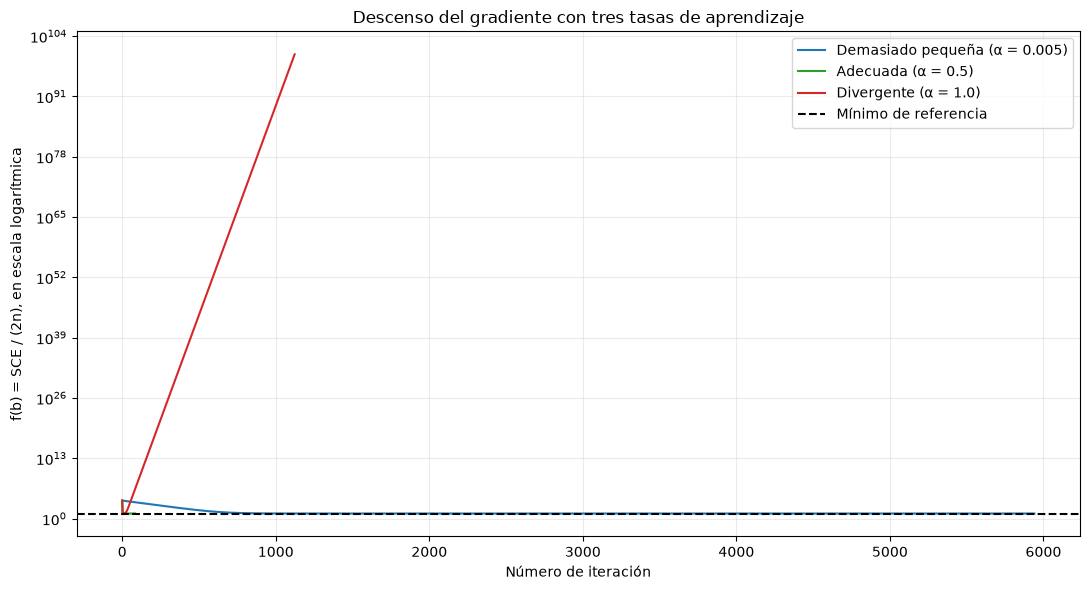

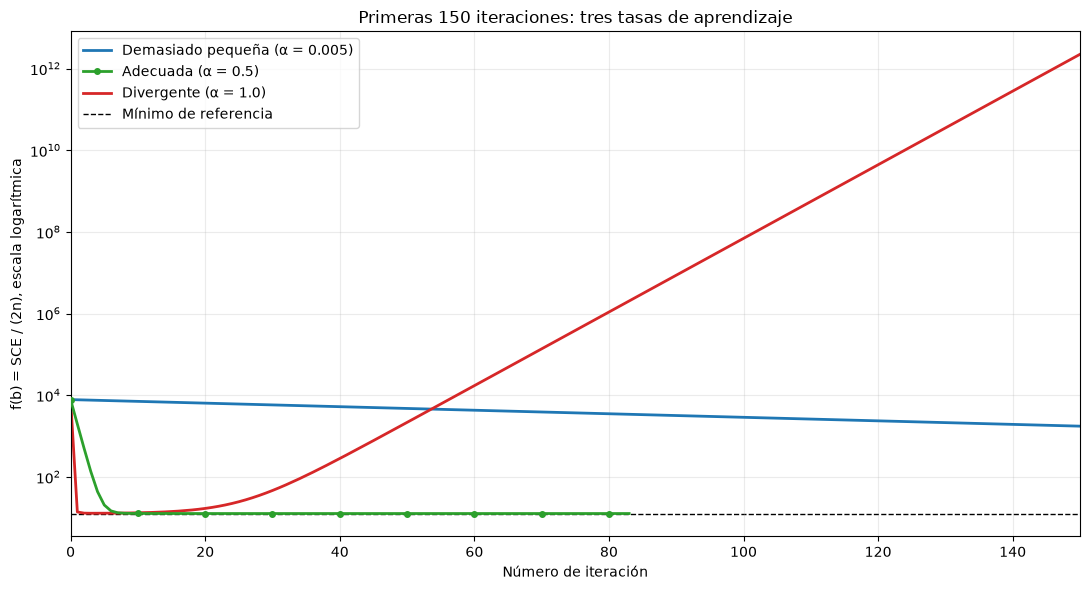

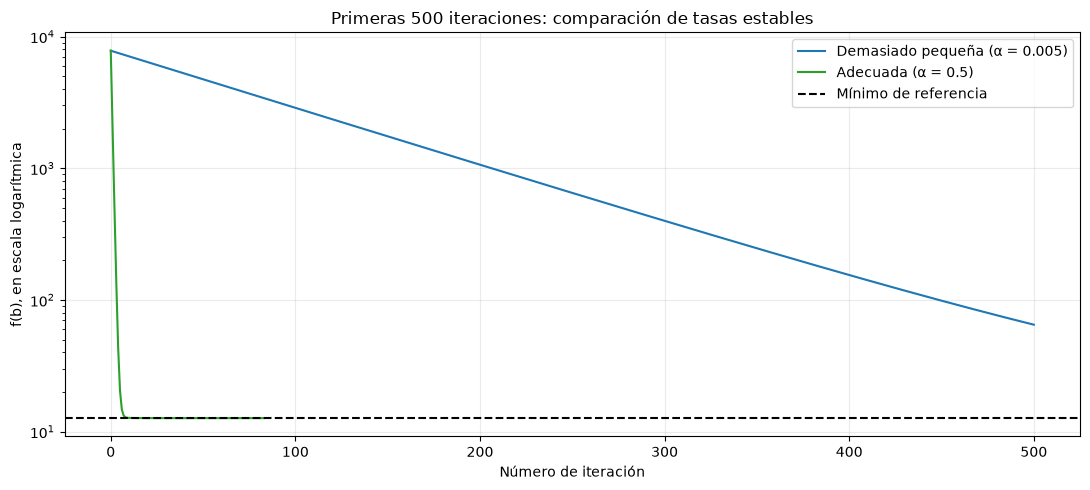


COMPARACIÓN EN LAS UNIDADES ORIGINALES
 Coeficiente  Descenso del gradiente  Mínimos cuadrados  Diferencia absoluta
  Intercepto        137.126948420114   137.127552179293       0.000603759179
   frequency         -0.001196114627    -0.001196133412       0.000000018785
       angle         -0.351479695279    -0.351565427109       0.000085731830
chord_length        -33.885085756131   -33.887292203710       0.002206447579
displacement       -164.074781429938  -164.044870140822       0.029911289115

Máxima diferencia absoluta entre predicciones: 0.0009306757212357297 dB
Diferencia entre el error de la tasa adecuada y el mínimo: 4.092152749990419e-08

MODELO FINAL POR DESCENSO DEL GRADIENTE
sound_level estimado = 137.126948420 -0.001196115 · frequency -0.351479695 · angle -33.885085756 · chord_length -164.074781430 · displacement


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CARGAR LOS DATOS
# ============================================================

datos = pd.read_csv(
    "../dataset/airfoil_self_noise.dat",
    sep=r"\s+",
    header=None,
    names=[
        "frequency", "angle", "chord_length",
        "velocity", "displacement", "sound_level"
    ]
)

variables = [
    "frequency",
    "angle",
    "chord_length",
    "displacement"
]

X_original = datos[variables].to_numpy(dtype=float)
y = datos["sound_level"].to_numpy(dtype=float)

n = len(y)

# ============================================================
# 2. ESTANDARIZAR LAS VARIABLES EXPLICATIVAS
# ============================================================

# Cada variable queda con promedio 0 y desviación estándar 1.
# La respuesta se mantiene en dB.
medias = X_original.mean(axis=0)
desvios = X_original.std(axis=0)

if np.any(desvios == 0):
    raise ValueError("Hay una variable explicativa sin variación.")

X_std = (X_original - medias) / desvios

# Agregar una columna de unos para incluir el intercepto.
X = np.column_stack((np.ones(n), X_std))

# ============================================================
# 3. DEFINIR LA FUNCIÓN DE ERROR Y SU GRADIENTE
# ============================================================

# f(b) = suma de errores al cuadrado / (2*n)
def funcion_error(b):
    errores = X @ b - y
    return np.sum(errores**2) / (2 * n)


# Gradiente correspondiente a la función anterior.
def gradiente(b):
    errores = X @ b - y
    return X.T @ errores / n


# ============================================================
# 4. CONFIGURACIÓN Y TASAS DE APRENDIZAJE
# ============================================================

TOLERANCIA = 1e-8
MAX_ITERACIONES = 10000
LIMITE_ERROR = 1e100

tasas = {
    "Demasiado pequeña": 0.005,
    "Adecuada": 0.5,
    "Divergente": 1.0
}

print("CONFIGURACIÓN")
print(f"Cantidad de observaciones: {n}")
print("Coeficientes iniciales: todos en cero")
print(f"Tolerancia para el cambio del error: {TOLERANCIA}")
print(f"Máximo de iteraciones: {MAX_ITERACIONES}")
print(f"Límite de seguridad del error: {LIMITE_ERROR:.0e}")

# ============================================================
# 5. IMPLEMENTAR EL DESCENSO DEL GRADIENTE
# ============================================================

def descenso_gradiente(
    alpha,
    max_iter=MAX_ITERACIONES,
    tolerancia=TOLERANCIA,
    limite_error=LIMITE_ERROR
):
    # Inicializar los cinco coeficientes en cero.
    b = np.zeros(X.shape[1])

    error_actual = funcion_error(b)
    historial = [error_actual]

    pasos = 0
    cambio_error = np.nan
    motivo = "Máximo de iteraciones alcanzado"

    for _ in range(max_iter):
        # Calcular el gradiente con los coeficientes actuales.
        g = gradiente(b)

        # Actualizar en dirección opuesta al gradiente.
        b_nuevo = b - alpha * g

        # Calcular el error después de actualizar.
        with np.errstate(over="ignore", invalid="ignore"):
            error_nuevo = funcion_error(b_nuevo)

        pasos += 1
        historial.append(error_nuevo)

        b = b_nuevo
        cambio_error = abs(error_nuevo - error_actual)

        # Protección para interrumpir una ejecución divergente.
        if not np.isfinite(error_nuevo) or error_nuevo > limite_error:
            motivo = "Interrupción por crecimiento excesivo del error"
            break

        # Criterio principal: cambio del error entre dos iteraciones.
        if cambio_error < tolerancia:
            motivo = "Cambio absoluto del error menor que la tolerancia"
            break

        error_actual = error_nuevo

    return {
        "coeficientes": b,
        "historial": np.asarray(historial),
        "iteraciones": pasos,
        "ultimo_cambio_error": cambio_error,
        "motivo": motivo
    }


# ============================================================
# 6. EJECUTAR LAS TRES TASAS
# ============================================================

resultados = {}

for nombre, alpha in tasas.items():
    resultado = descenso_gradiente(alpha)
    resultado["alpha"] = alpha
    resultados[nombre] = resultado

    print(f"\nCASO: {nombre}")
    print(f"Tasa de aprendizaje: {alpha}")
    print(f"Iteraciones: {resultado['iteraciones']}")
    print(f"Error final f(b): {resultado['historial'][-1]:.12e}")
    print(
        "Último cambio absoluto del error:",
        f"{resultado['ultimo_cambio_error']:.12e}"
    )
    print(f"Motivo de detención: {resultado['motivo']}")

# ============================================================
# 7. OBTENER EL MÍNIMO DE REFERENCIA
# ============================================================

# Mínimos cuadrados sobre la misma matriz estandarizada.
b_referencia_std = np.linalg.lstsq(X, y, rcond=None)[0]
error_minimo = funcion_error(b_referencia_std)

print(f"\nError mínimo de referencia f(b): {error_minimo:.12f}")

# Comparar el progreso en la iteración 100.
iteracion_comun = 100

print(f"\nERROR EN LA ITERACIÓN {iteracion_comun}")

for nombre, resultado in resultados.items():
    historial = resultado["historial"]

    if len(historial) > iteracion_comun:
        print(f"{nombre}: {historial[iteracion_comun]:.12e}")
    else:
        print(
            f"{nombre}: terminó en la iteración "
            f"{resultado['iteraciones']}, con error "
            f"{historial[-1]:.12e}"
        )

# ============================================================
# 8. GRÁFICO COMPLETO CON LAS TRES TASAS
# ============================================================

colores = {
    "Demasiado pequeña": "tab:blue",
    "Adecuada": "tab:green",
    "Divergente": "tab:red"
}

fig, ax = plt.subplots(figsize=(11, 6))

for nombre, resultado in resultados.items():
    historial = resultado["historial"]
    iteraciones = np.arange(len(historial))

    validos = np.isfinite(historial) & (historial > 0)

    ax.plot(
        iteraciones[validos],
        historial[validos],
        color=colores[nombre],
        label=f"{nombre} (α = {resultado['alpha']})"
    )

ax.axhline(
    error_minimo,
    color="black",
    linestyle="--",
    label="Mínimo de referencia"
)

ax.set_yscale("log")
ax.set_xlabel("Número de iteración")
ax.set_ylabel("f(b) = SCE / (2n), en escala logarítmica")
ax.set_title("Descenso del gradiente con tres tasas de aprendizaje")
ax.legend()
ax.grid(True, alpha=0.25)

fig.tight_layout()
plt.show()

# ============================================================
# 9. GRÁFICO DE LAS PRIMERAS 150 ITERACIONES
# ============================================================

# Permite distinguir las tres curvas sin mostrar toda la
# magnitud final del error divergente.
fig, ax = plt.subplots(figsize=(11, 6))

for nombre, resultado in resultados.items():
    historial = resultado["historial"]
    cantidad = min(len(historial), 151)

    ax.plot(
        np.arange(cantidad),
        historial[:cantidad],
        color=colores[nombre],
        linewidth=2,
        marker="o" if nombre == "Adecuada" else None,
        markevery=10,
        markersize=4,
        zorder=3 if nombre == "Adecuada" else 2,
        label=f"{nombre} (α = {resultado['alpha']})"
    )

ax.axhline(
    error_minimo,
    color="black",
    linestyle="--",
    linewidth=1,
    zorder=1,
    label="Mínimo de referencia"
)

ax.set_yscale("log")
ax.set_xlim(0, 150)
ax.set_xlabel("Número de iteración")
ax.set_ylabel("f(b) = SCE / (2n), escala logarítmica")
ax.set_title("Primeras 150 iteraciones: tres tasas de aprendizaje")
ax.legend()
ax.grid(True, alpha=0.25)

fig.tight_layout()
plt.show()

# ============================================================
# 10. CONVERTIR LOS COEFICIENTES A LAS UNIDADES ORIGINALES
# ============================================================

def convertir_coeficientes(b_std):
    pendientes = b_std[1:] / desvios
    intercepto = b_std[0] - np.sum(medias * pendientes)

    return np.concatenate(([intercepto], pendientes))


# Utilizar el resultado de la tasa adecuada.
b_gradiente = convertir_coeficientes(
    resultados["Adecuada"]["coeficientes"]
)

# Referencia de mínimos cuadrados en las unidades originales.
X_original_intercepto = np.column_stack((
    np.ones(n),
    X_original
))

b_referencia = np.linalg.lstsq(
    X_original_intercepto,
    y,
    rcond=None
)[0]

# ============================================================
# 11. COMPARAR LOS COEFICIENTES Y LAS PREDICCIONES
# ============================================================

comparacion = pd.DataFrame({
    "Coeficiente": ["Intercepto"] + variables,
    "Descenso del gradiente": b_gradiente,
    "Mínimos cuadrados": b_referencia,
    "Diferencia absoluta": np.abs(b_gradiente - b_referencia)
})

print("\nCOMPARACIÓN EN LAS UNIDADES ORIGINALES")
print(comparacion.to_string(
    index=False,
    float_format=lambda valor: f"{valor:.12f}"
))

y_gradiente = X_original_intercepto @ b_gradiente
y_referencia = X_original_intercepto @ b_referencia

print(
    "\nMáxima diferencia absoluta entre predicciones:",
    np.max(np.abs(y_gradiente - y_referencia)),
    "dB"
)

print(
    "Diferencia entre el error de la tasa adecuada y el mínimo:",
    abs(resultados["Adecuada"]["historial"][-1] - error_minimo)
)

# ============================================================
# 12. MOSTRAR EL MODELO FINAL
# ============================================================

ecuacion = f"sound_level estimado = {b_gradiente[0]:.9f}"

for variable, coeficiente in zip(variables, b_gradiente[1:]):
    ecuacion += f" {coeficiente:+.9f} · {variable}"

print("\nMODELO FINAL POR DESCENSO DEL GRADIENTE")
print(ecuacion)